In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# v4와 동일한 weighting method 비교(FP-only vs IMG-only vs UNIFORM vs CUE)이지만,
# 이번엔 Kd의 PI / WS2만 그리고, RMSE(막대, 왼쪽 축)와 PCC(선, 오른쪽 축)를
# 한 그림에 같이 그리는 dual-axis 버전이다.
cue_base = '/data/rlawlsgurjh/work/gitlab/CUE/cue/results'

datasets = ['DIS']
targets = ['PI', 'WS2']
metrics_of_interest = ['rmse', 'pcc']

# 비교할 소스: (표시 이름, metrics.csv 루트 경로). CUE는 항상 마지막에 오도록 순서를 고정한다.
model_sources = {
    'FP': os.path.join(cue_base, '{dataset}', '{target}', 'v1', 'FP'),
    'IMG': os.path.join(cue_base, '{dataset}', '{target}', 'v1', 'IMG'),
    'UNIFORM': os.path.join(cue_base, '{dataset}', '{target}', 'v1', 'UNIFORM'),
    'CUE': os.path.join(cue_base, '{dataset}', '{target}', 'v1', 'CUE'),
}

model_order = ['IMG', 'FP', 'UNIFORM', 'CUE']

# target별 PCC(오른쪽 축) y축 하한선
PCC_YMIN = {
    'PI': 0.1,
    'WS2': 0.1,
}

In [2]:
def load_metric(model_dir_template, dataset, target):
    """cmfe의 metrics.csv(train.py::aggregate_metrics 출력)를 읽어
    model_name == 'mlp' 행의 rmse/pcc(+ _std)를 뽑아온다."""
    metrics_path = os.path.join(model_dir_template.format(dataset=dataset, target=target), 'metrics.csv')
    if not os.path.exists(metrics_path):
        return None

    df_m = pd.read_csv(metrics_path)
    mlp_row = df_m[df_m['model_name'] == 'mlp']
    if mlp_row.empty:
        return None

    values = {}
    for col in mlp_row.columns:
        if col in ['model_name', 'Unnamed: 0']:
            continue
        norm_col = col.lower()
        if norm_col in metrics_of_interest or norm_col.replace('_std', '') in metrics_of_interest:
            values[norm_col] = mlp_row[col].values[0]
    return values if values else None


raw_rows = []
for d_name in datasets:
    for target in targets:
        for model_name, dir_template in model_sources.items():
            vals = load_metric(dir_template, d_name, target)
            if vals is not None:
                raw_rows.append({'Dataset': d_name, 'Target': target, 'Model': model_name, **vals})

df_total = pd.DataFrame(raw_rows)
expected = len(datasets) * len(targets) * len(model_sources)
print(f"데이터 로드 완료: {len(df_total)}개의 항목이 수집되었습니다 (기대값: {expected}).")

데이터 로드 완료: 8개의 항목이 수집되었습니다 (기대값: 8).


In [3]:
def plot_rmse_pcc_dual(df_plot, dataset, target_name, output_dir):
    """RMSE는 막대(왼쪽 축), PCC는 선+마커(오른쪽 축)로 그린다.
    additional_Plot.ipynb와 동일하게 CUE만 색을 넣고 나머지는 회색 + 해치 패턴으로 구분한다
    (단, IMG는 해치 없이 플레인 회색)."""
    df_target = df_plot.set_index('Model').reindex(model_order).dropna(subset=['rmse', 'pcc']).reset_index()
    if df_target.empty:
        return

    models = df_target['Model'].tolist()
    rmse_values = [round(v, 3) for v in df_target['rmse'].tolist()]
    pcc_values = [round(v, 3) for v in df_target['pcc'].tolist()]

    highlight_color = '#ef476f'
    no_hatch_models = ('CUE', 'IMG')
    baseline_hatches = ['///', '\\\\', '|||']

    bar_colors = ['lightgray'] * len(models)
    if 'CUE' in models:
        bar_colors[models.index('CUE')] = highlight_color

    x = np.arange(len(models))

    rmse_min, rmse_max = min(rmse_values), max(rmse_values)
    rmse_margin = (rmse_max - rmse_min) * 0.45 if (rmse_max - rmse_min) != 0 else 0.1

    pcc_ymin = PCC_YMIN.get(target_name, 0.3)
    pcc_max = max(pcc_values)
    pcc_margin = (pcc_max - pcc_ymin) * 0.25 if (pcc_max - pcc_ymin) != 0 else 0.1

    fig, ax1 = plt.subplots(figsize=(6, 4))
    ax2 = ax1.twinx()

    bars = ax1.bar(x, rmse_values, color=bar_colors, edgecolor='black', alpha=0.9, linewidth=1)

    hatch_i = 0
    for i, bar in enumerate(bars):
        if models[i] not in no_hatch_models:
            bar.set_hatch(baseline_hatches[hatch_i % len(baseline_hatches)])
            hatch_i += 1
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2., height + (rmse_margin * 0.03),
                  f'{height:.3f}', ha='center', va='bottom', fontsize=13, fontweight='bold')

    ax2.plot(x, pcc_values, color='black', marker='o', markersize=5, linewidth=2, zorder=5)
    for xi, yi in zip(x, pcc_values):
        ax2.annotate(f'{yi:.3f}', xy=(xi, yi), xytext=(0, 16), textcoords='offset points',
                     ha='center', va='bottom', fontsize=12, fontweight='bold', color='black', zorder=6)

    ax1.set_title("")
    ax1.set_xlabel("")
    ax1.set_ylabel("")
    ax2.set_ylabel("")
    ax1.set_xticklabels([])

    ax1.tick_params(axis='y', labelsize=11)
    ax2.tick_params(axis='y', labelsize=11)
    ax1.tick_params(axis='x', which='both', length=0)

    ax1.grid(axis='y', linestyle='--', alpha=0.5)
    for spine in ax1.spines.values():
        spine.set_visible(True)

    ax1.set_ylim(max(0, rmse_min - (rmse_margin * 0.1)), rmse_max + rmse_margin)
    ax2.set_ylim(pcc_ymin, pcc_max + pcc_margin)

    plt.tight_layout()
    os.makedirs(output_dir, exist_ok=True)
    save_path = os.path.join(output_dir, f"{target_name}_rmse_pcc.png")
    plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"저장 완료: {save_path}")

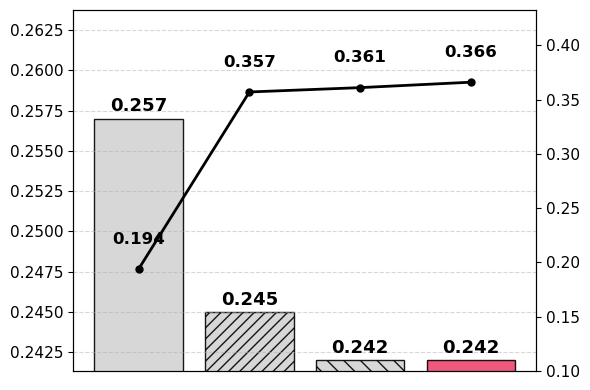

저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/weight_comparison_v6/DIS/PI_rmse_pcc.png


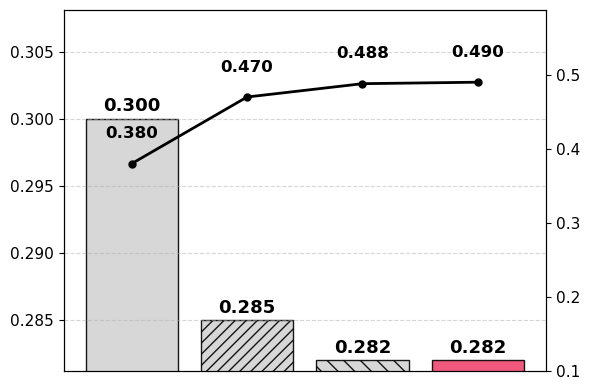

저장 완료: /data/rlawlsgurjh/work/gitlab/CUE/cmfe/results/plots/weight_comparison_v6/DIS/WS(alpha=2)_rmse_pcc.png


In [4]:
plot_base_dir = os.path.join(cue_base, 'plots', 'weight_comparison_v6')

for d_name in datasets:
    for target in targets:
        df_target = df_total[(df_total['Dataset'] == d_name) & (df_total['Target'] == target)]
        if df_target.empty:
            continue

        g_name = 'DIS' if d_name == 'DIS' else 'INH'
        output_path = os.path.join(plot_base_dir, g_name)
        plot_rmse_pcc_dual(df_target, d_name, target, output_path)